# 🧩 Mini-Lab: Environment Setup

**Module 1: Ship a Working AI Feature Today** | **Type: Mini-Lab**

---

## Learning Objectives

By the end of this mini-lab, you will be able to:

1. **Set up** your IDE, Git, and uv so you can work in a Python project
2. **Clone** the course repository and create a project virtual environment with `uv sync`
3. **Explain** how a virtual environment keeps this project's packages separate from other projects
4. **Use** `uv.lock` to pin exact dependency versions so installs are repeatable

## Target Concepts

| Concept | Gloss |
|---------|-------|
| Virtual environment | A virtual environment is an isolated workspace that keeps a project’s Python packages and settings separate, so installs and upgrades do not break other projects. |

## Course repo

> **Instructor note:** The only course-specific value in this notebook is the clone URL below. Update it for each course; everything else stays the same.

```bash
git clone https://github.com/techbricks/Python-for-AI-Engineering
cd Python-for-AI-Engineering
```

## 1. Install an IDE

We'll use [Cursor](https://cursor.com) — an AI-powered IDE built on VS Code. If you prefer **VS Code** or another IDE, that works too.

### Installation

1. Download from [cursor.com](https://cursor.com/download)
2. Install for your platform (Mac / Windows / Linux)

### Recommended Extensions

- **Python** — Microsoft's Python extension
- **Jupyter** — For notebook support

### Configure Python Interpreter (after your venv exists)

You will create the virtual environment in a later step. After it exists:

1. Press `Ctrl+Shift+P` (Windows) or `Cmd+Shift+P` (Mac)
2. Type "Python: Select Interpreter"
3. Choose the interpreter from your virtual environment:
   - Mac/Linux: `.venv/bin/python`
   - Windows: `.venv\Scripts\python.exe`


## 2. Install Git

Git is required to clone the course repository.

### Quick check

| Platform | Command / Action |
|----------|------------------|
| **macOS** | Run `git --version` — macOS will prompt to install if needed |
| **Windows** | Download from [git-scm.com](https://git-scm.com/download/win) |
| **Linux** | `sudo apt install git` (Debian/Ubuntu) or `sudo dnf install git` (Fedora) |

### macOS

```bash
git --version
```

If Git is not installed, macOS will automatically prompt:

> "The git command requires the command line developer tools."

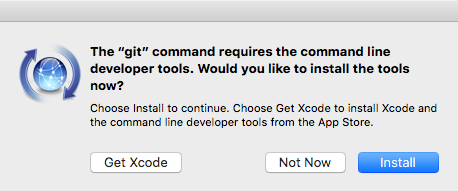

Click **Install** and wait for it to finish:

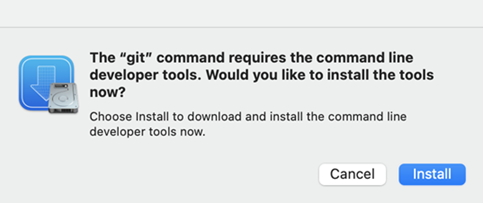

### Windows (Git Bash)

Windows needs **Git for Windows**, which also gives you **Git Bash** — the terminal we use for the rest of this lab.

1. Download and install [Git for Windows](https://git-scm.com/download/win)

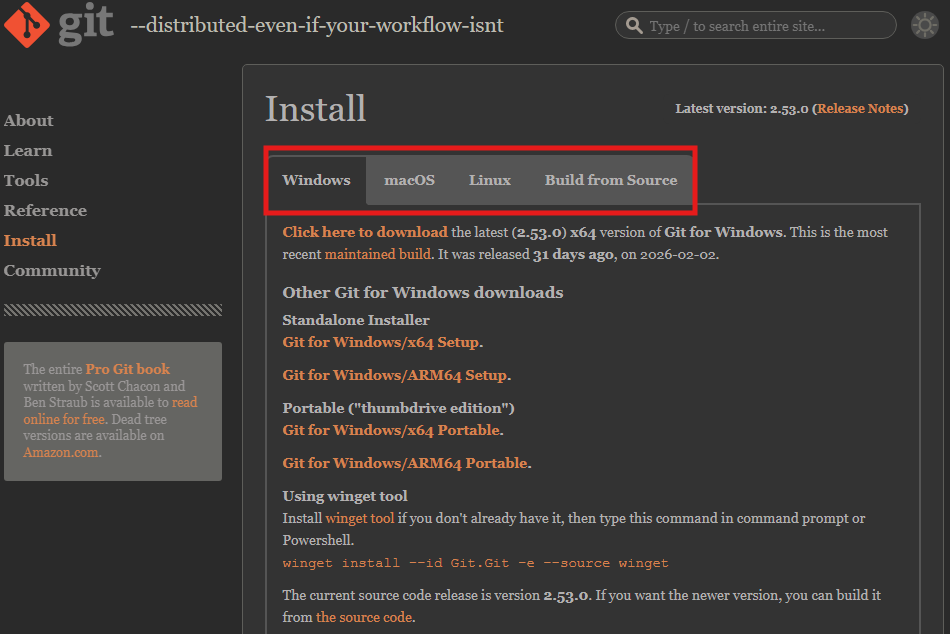

2. During install, select:
   - "Git Bash Here"
   - "Use Git from the command line and third-party software"

3. Open **Git Bash** and verify:

```bash
git --version
```

From this point on, bash commands are the same on Mac, Windows (Git Bash), and Linux.

### Verify (everyone)

```bash
git --version
which git
```

📖 Detailed instructions: [Git Installation Guide](./guide/git-installation-guide.md)


## 3. Clone the Course Repository

```bash
git clone https://github.com/techbricks/Python-for-AI-Engineering
cd Python-for-AI-Engineering
```

> **Tip:** Open the cloned folder as your project root in Cursor (**File → Open Folder**) instead of only using `cd`.

The cloned repository includes:

- `pyproject.toml` — the packages this project needs
- `uv.lock` — the exact versions to install (the pin file)
- Course notebooks and lab code


## 4. Install uv Package Manager

[uv](https://github.com/astral-sh/uv) is a fast Python package manager. It creates the virtual environment and installs pinned packages for this course.

It is written in Rust and 10–100× faster than pip.

### Option 1 — Official Installer (recommended)

Use this in a bash-style terminal (macOS/Linux Terminal, or **Git Bash** on Windows):

```bash
curl -LsSf https://astral.sh/uv/install.sh | sh
```

> **Windows users:** Restart Git Bash after install so PATH updates are picked up.

### Option 2 — pip (if Python is already installed)

```bash
pip install uv
```

### Verify

```bash
uv --version
```

> 📖 Detailed instructions: [uv Installation Guide](guide/uv-installation-guide.md)


## 5. Two Ways to Use uv

uv supports two workflows. This lab uses the **project-style** workflow with a lockfile.

| Feature | pip-style | project-style (this lab) |
|---------|-----------|---------------------------|
| **Command** | `uv pip install -r requirements.txt` | `uv add` + `uv sync` |
| **Config file** | `requirements.txt` | `pyproject.toml` |
| **Lockfile** | None | `uv.lock` (auto-generated) |
| **Repeatable installs** | You pin versions by hand | Automatic from the lockfile |
| **Best for** | Quick scripts | Course labs and shared projects |

### project-style (what we use)

```bash
uv init                    # Creates pyproject.toml
uv add httpx               # Adds a package and updates uv.lock
uv sync                    # Installs exact versions from the lockfile
```

- `pyproject.toml` → lists the packages the project needs
- `uv.lock` → pins exact versions (auto-generated)
- `.venv/` → your virtual environment (created by `uv sync`)

When you run `uv sync`, it reads `uv.lock` and installs the **same versions** every time.

> **This course repo already has `pyproject.toml` and `uv.lock`.** Do not run `uv init` inside it. The commands above show how a new project is created. For this lab, the command you run is `uv sync` (next sections).


## 6. Common uv Commands

You will use `uv sync` in this lab. The rest of the table is the cheat sheet for later, when you start your own projects.

| Command | Description |
|---------|-------------|
| `uv init` | Initialize a new project |
| `uv add <package>` | Add a dependency and update the lockfile |
| `uv add <package> --dev` | Add a dev-only dependency (tests, notebooks) |
| `uv sync` | Create `.venv` and install pinned versions from `uv.lock` |
| `uv run python script.py` | Run a script inside the virtual environment |
| `uv run jupyter notebook` | Run Jupyter inside the virtual environment |

```bash
# Add a single package
uv add httpx

# Add several packages
uv add httpx pandas

# Add with a version constraint
uv add "httpx>=0.27"

# Add a dev dependency
uv add pytest --dev
```


## 7. Virtual Environments

> 🧩 **Virtual environment.** Isolated workspace that keeps this project's packages from breaking others.
> Watch for `.venv` in the interpreter path after `uv sync`.

A **virtual environment** is a private folder (usually named `.venv`) that holds this project's Python packages.

Without one, every project on your computer shares the same packages. Installing a new library for project A can break project B.

Think of `.venv` as a labeled lunchbox: this project's packages stay in this box, and other projects keep their own.

You do **not** create it with a separate `python -m venv` command in this lab. `uv sync` creates `.venv` for you.

Do **not** commit the `.venv` folder. Commit `pyproject.toml` and `uv.lock` instead — anyone can recreate the same environment from those two files.


## 8. Install Course Dependencies

Once the course folder is open (cloned) and has `pyproject.toml` + `uv.lock`, run this **in the project root**:

```bash
uv sync
```

That command:

- Creates a `.venv` virtual environment
- Installs **exact** dependency versions from `uv.lock`
- Matches the environment the lockfile was built with

Then select the `.venv` Python interpreter in Cursor (see §1) and open this notebook from that environment.


### Check that the notebook is using `.venv`

Run the cell below. The printed path should include `.venv`. If it does not, select the interpreter from §1 and re-run.


In [ ]:
import sys

print("You are running Python from:")
print(sys.executable)
print()

path = sys.executable.replace("\\", "/")
if ".venv" in path:
    print("This looks like the project virtual environment. You are set.")
else:
    print("This path does not include .venv.")
    print("In your IDE: Python: Select Interpreter → choose .venv, then re-run this cell.")


## 9. Dependency Pinning

A virtual environment **isolates** packages. It does **not** freeze versions.

If you install a package with no pin, you get today's latest release. A classmate who installs next month may get a different release — and the code can break.

**Pinning** means writing down the exact version of every package so `uv sync` always rebuilds the same environment.

In this lab, the pin file is `uv.lock`. You do not edit it by hand. `uv add` and `uv sync` keep it up to date.

In [ ]:
from IPython.display import display, Markdown

def md(text):
    """Display text as rendered markdown."""
    display(Markdown(text))


md("""
### Unpinned vs pinned (with uv)

| Style | What you give the installer | What you get next month |
|-------|-----------------------------|-------------------------|
| **Unpinned** | A package name, no lockfile | Whatever version is newest that day |
| **Pinned** | `uv.lock` + `uv sync` | The same versions the lockfile recorded |

`pyproject.toml` lists the packages the project needs. `uv.lock` pins the **exact** version of every package, including packages pulled in by other packages. That is what makes `uv sync` repeatable.
""")


## 🎯 Summary

### Key Takeaways

1. **Tooling** — Cursor (or VS Code), Git, and uv give you a workspace; clone the course repo to get the materials
2. **Virtual environment** — `.venv` keeps this project's packages separate so installs do not break other projects
3. **`uv sync`** — creates `.venv` and installs the exact versions from `uv.lock`
4. **Dependency pinning** — the lockfile records exact versions so installs stay repeatable on any machine
